In [1]:
from pathlib import Path
import re
import json 
import sys
import os

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib notebook
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

module_path = os.path.abspath(os.path.join('../'))
if module_path not in sys.path:
    sys.path.append(module_path)


In [2]:
font_size = 24
matplotlib.rcParams['font.size'] = font_size
matplotlib.rcParams["font.weight"] = "bold"
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['axes.labelsize'] = font_size
matplotlib.rcParams['axes.titlesize'] = 28
matplotlib.rcParams['legend.fontsize'] = font_size
matplotlib.rcParams['xtick.labelsize'] = font_size
matplotlib.rcParams['ytick.labelsize'] = font_size
#matplotlib.rcParams['text.latex.preamble']=r'\usepackage{amsmath} \DeclareMathOperator{\F}{F} \DeclareMathOperator{\GMF}{GMF} \DeclareMathOperator{\MLP}{MLP}'

In [3]:
def read_tb_file(tb_file):
    ea = event_accumulator.EventAccumulator(str(tb_file),
                                            size_guidance={ 
                                                event_accumulator.COMPRESSED_HISTOGRAMS: 0,
                                                event_accumulator.IMAGES: 0,
                                                event_accumulator.AUDIO: 0,
                                                event_accumulator.SCALARS: 0,
                                                event_accumulator.HISTOGRAMS: 0,})
    ea.Reload()
    return ea

def create_df_from_ea(ea, tag):
    steps = [x.step for x in ea.Scalars(tag)]
    values = [x.value for x in ea.Scalars(tag)]
    t0 = ea.Scalars(tag)[0].wall_time
    time = [x.wall_time-t0 for x in ea.Scalars(tag)]

    df = pd.DataFrame({"Time": time, "Step": steps, "Value": values})
    return df

def get_hparams_from_ea(ea):
    hparams_string = ea.Tensors('hyperparameters/text_summary')[0].tensor_proto.string_val[0].decode()
    hparams_l = hparams_string.replace('|\n|',',').replace('|',':').replace(':param:value,-:-,','').split(',')
    keys = [i.split(':')[0] for i in hparams_l if len(i.split(':'))>1]
    values = [i.split(':')[1] for i in hparams_l if len(i.split(':'))>1]
        
    d = {k:v for k,v in zip(keys,values)}
    
    return d

def create_mu_std_df_from_ea(ea_dict, tag, filter_best=False, n_best=5):
    min_len = 1e6
    
    df_list = []
    for name, ea in ea_dict.items():
        df = create_df_from_ea(ea, tag)
        if len(df) < min_len:
            min_len = len(df)
        df_list.append(df)

    return create_mu_std_df(df_list, filter_best, n_best)

def create_mu_std_df(df_list, filter_best=False, n_best=5):
    print(df_list)
    val_list = []
    for df in df_list:
        val_list.append(df["Value"])
    val_list = np.array(val_list)
    
    means = np.mean(val_list, axis=-1)
    idx = np.argsort(-means)
    if filter_best:
        vals = val_list[idx[:n_best]]
    else:
        vals = val_list
    x_axis = df_list[0]["Step"][:min_len]
    
    mu = np.mean(vals, axis=0)
    median = np.median(vals, axis=0)
    std = np.std(vals, axis=0)
    q1 = np.quantile(vals, 0.25, axis=0)
    q3 = np.quantile(vals, 0.75, axis=0)
    best = val_list[idx[0]]
    return pd.DataFrame({"Step": x_axis, "mu": mu, "std": std, "best": best, "median": median, "q1": q1, "q3": q3})

def load_dirs(tasks_dir, tags, save_path=None):
    # init dicts
    df_dict = {}
    for tag in tags:
        df_dict[tag] = {}
        
    for task_dir in tqdm(tasks_dir.iterdir()):        
        ea_dict = {}

        if len(list((task_dir).iterdir())) > 0:
            try:
                ea_dict[task_dir] = read_tb_file(task_dir)
            except:
                print(f"WARNING: No data in {run_dir}. Skipped.")
                continue

        if ea_dict:
            for tag in tags:
                df_dict[tag][task_dir.name] = create_mu_std_df(
                    ea_dict, tag, filter_best=True, n_best=5).copy()
    
    if save_path:
        with open(save_path, 'wb') as handle:
            pkl.dump(df_dict, handle, protocol=pkl.HIGHEST_PROTOCOL)
    return df_dict

def plot_mu_std(x_axis, mu, q1=None, q3=None, std=None, fig=None, title=None, label='', yuplim=None, 
                ydownlim=None, interpolate=False, max_num_tasks=None):
    if fig is None:
        fig = plt.figure(figsize=[12,10])
        
    if interpolate:
        from scipy.interpolate import make_interp_spline, BSpline
        std = std[::2]
        new_size = std.shape[0]
        
        xnew = np.linspace(x_axis.min(), x_axis.max(), new_size)
        spl = make_interp_spline(x_axis, mu, k=3)  # type: BSpline
        power_smooth = spl(xnew)
        
        x_axis = xnew
        power_smooth = np.clip(power_smooth, np.min(mu), np.max(mu))
        mu = power_smooth

    if std is not None:
        uperror = mu+std
        downerror = mu-std
        
        uperror = np.clip(uperror, np.min(mu), np.max(mu))
        downerror = np.clip(downerror, np.min(mu), np.max(mu))
    else:
        uperror = q3
        downerror = q1    
    
    if yuplim is not None:
        uperror = np.where(uperror > yuplim, yuplim, uperror)
    if ydownlim is not None:
        downerror = np.where(downerror < ydownlim, ydownlim, downerror)
    plt.plot(x_axis, mu, label=label)
    plt.fill_between(x_axis, downerror, uperror, alpha=.1)
    plt.xlabel("Timesteps", fontsize=16)
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)
    
    if title is not None:
        plt.title(title)

#     plt.ticklabel_format(axis="x", style="sci", scilimits=(0,0))
    if max_num_tasks:
        plt.yticks(np.arange(max_num_tasks+1), 
                   ["{0:1.1f}\%".format(100.0 * i/max_num_tasks) for i in np.arange(max_num_tasks+1)])
#     plt.legend(loc="lower right")
#     plt.legend(loc="upper left")
    
    return fig

def create_mean_std_plot(ea_dict, tag,  title, smoothing=3.0, savefig_fmt=None, filter_best=False):
    df = create_mu_std_df(ea_dict, tag)
    fig = plot_mu_std(title, 'forward',df["steps"], df["mu"], df["std"])
    if savefig_fmt is not None:
        plt.savefig(title + '.' + savefig_fmt, format=savefig_fmt, dpi=300)
        
    return fig

def parse_fname(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)
    seed = intgr[-4]
    n_epc = intgr[-1]
    n_epi = intgr[-2]
    if len(floats) > 0:
        irm_coeff = floats[0]
    else:
        irm_coeff = 0
        
    return int(seed), float(irm_coeff), name

In [4]:
tags = ["charts/episodic_return", "eval/mu"]
#run_dir_swil = Path("runs/2905_swil_ae")
run_dir_comp = Path("../runs/sac_airl_reg_comp")

#df_dict = load_dirs(run_dir, tags)

In [5]:
###

In [6]:
ea_dict = {}

def load_to_dict(p):
    ea = read_tb_file(p)
    ea_dict[p] = ea
    
    return ea 

with ThreadPoolExecutor(20) as executor:
    futures = [executor.submit(load_to_dict, p) for p in run_dir_comp.iterdir()]

for f in futures:
    print(f.result())

In [8]:
print(len(ea_dict.keys()))

140


In [34]:
seeds = [515, 234, 894, 72, 322]
algos = ['sac']
disc_types = ['gail', 'airl']
# irm_coeffs = [0.0, 0.1, 1.0, 10.0, 100.0]
envs = ['Ant-v3']
# lins = ['--use_spectral_norm', '--use_weight_norm', '']
lins = ['--use_spectral_norm', '', '--lip_coeff=1.0', '--lip_coeff=10.0', '--irm_coeff=1.0', '--irm_coeff=10.0', '--lip_coeff=10.0--irm_coeff=1.0']
# lins = ['--use_weight_norm --linear_proj']
# usenobs = ['--use_next_obs', '', '--use_next_obs --use_dones']
# usenobs = ['--use_next_obs', '', '--use_next_obs --use_dones']
n_demos = [10]
disc_nonlins = ['tanh']
usenobs = ['', '--use_actions']
# f"--gpus=gtx_1080:1 "

d = {}

for env_name in envs:
    d[env_name] = {}
    for seed in seeds:
        d[env_name][seed] = {}
        for n_demo in n_demos:
            d[env_name][seed][f"nd_{n_demo}"]  = {}
            for lin in lins:
                d[env_name][seed][f"nd_{n_demo}"][lin]  = {}
                for ua in usenobs:
                    d[env_name][seed][f"nd_{n_demo}"][lin][ua]  = {}
                    for d_nl in disc_nonlins:
                        d[env_name][seed][f"nd_{n_demo}"][lin][ua][d_nl]  = {}
                        for d_t in disc_types:
                            d[env_name][seed][f"nd_{n_demo}"][lin][ua][d_nl][d_t]  = {}

                                        
d_mustd = {}

for env_name in envs:
    d_mustd[env_name] = {}
    for n_demo in n_demos:
        d_mustd[env_name][f"nd_{n_demo}"]  = {}
        for lin in lins:
            d_mustd[env_name][f"nd_{n_demo}"][lin]  = {}
            for ua in usenobs:
                d_mustd[env_name][f"nd_{n_demo}"][lin][ua]  = {}
                for d_nl in disc_nonlins:
                    d_mustd[env_name][f"nd_{n_demo}"][lin][ua][d_nl]  = {}
                    for d_t in disc_types:
                        d_mustd[env_name][f"nd_{n_demo}"][lin][ua][d_nl][d_t]  = {}                                        
                        
def parse_fname_irm(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #print(m)
    #irm = int(m.group(1))

    if len(floats) > 0:
        irm_coeff = floats[0]
    else:
        irm_coeff = 0

    return int(seed), float(irm_coeff), name

def parse_fname_il(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    np = re.search('np(\d+)', fname, re.IGNORECASE)
    #np = int(np.group(1))
    np = 0
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #irm = int(m.group(1))

    return int(seed), np, name

def parse_fname_baselines(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    dt = ''
    if 'airl' in fname:
        dt = 'airl'
    elif 'gail' in fname:
        dt = 'gail'
    else:
        dt = 'pwil'
        
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #irm = int(m.group(1))

    return int(seed), dt, name

In [36]:
for k, v in ea_dict.items():
    hparams = get_hparams_from_ea(v)
    #df = create_df_from_ea(v, tags[-1])
    
    lin_string = ""
    if hparams['use_weight_norm'] == 'True':
        lin_string += "--use_weight_norm"
    if hparams['use_spectral_norm'] == 'True':
        lin_string += "--use_spectral_norm"
    if float(hparams['lip_coeff']) > 0:            
        lin_string += f"--lip_coeff={hparams['lip_coeff']}"
    if float(hparams['irm_coeff']) > 0:            
        lin_string += f"--irm_coeff={hparams['irm_coeff']}"
    #if hparams['use_absorb_wrapper'] == 'True':
    #    lin_string += "--use_absorb_wrapper"

    
    nob_string = ""
    if hparams['use_actions'] == 'True':
        nob_string += "--use_actions"
    d_nl = hparams['disc_nonlin']
    
    seed, _, name = parse_fname_irm(str(k))        
    ec = hparams['ent_coef']
    env_name = name[0]+'3'

    if 'gail' in str(k):
        disc_type = 'gail'
    elif 'airl' in str(k):
        disc_type = 'airl'
    elif 'swil' in str(k):
        disc_type = 'swil'
    else:
        disc_type = 'wail'
        
    #d_nl = hparams['disc_nonlin']
    #if d_nl == 'tanh':
    d[env_name][seed][f"nd_{hparams['n_demos']}"][lin_string][nob_string][d_nl][disc_type] = v



In [37]:
d

{'Ant-v3': {515: {'nd_10': {'--use_spectral_norm': {'': {'tanh': {'gail': <tensorboard.backend.event_processing.event_accumulator.EventAccumulator at 0x177b514f0>,
       'airl': <tensorboard.backend.event_processing.event_accumulator.EventAccumulator at 0x177b63cd0>}},
     '--use_actions': {'tanh': {'gail': <tensorboard.backend.event_processing.event_accumulator.EventAccumulator at 0x177b43070>,
       'airl': <tensorboard.backend.event_processing.event_accumulator.EventAccumulator at 0x177b227f0>}}},
    '': {'': {'tanh': {'gail': <tensorboard.backend.event_processing.event_accumulator.EventAccumulator at 0x177b63970>,
       'airl': <tensorboard.backend.event_processing.event_accumulator.EventAccumulator at 0x177b43cd0>}},
     '--use_actions': {'tanh': {'gail': <tensorboard.backend.event_processing.event_accumulator.EventAccumulator at 0x177b4c850>,
       'airl': <tensorboard.backend.event_processing.event_accumulator.EventAccumulator at 0x177b22fa0>}}},
    '--lip_coeff=1.0': {'

In [23]:
def get_all_keys(d):
    # recursive routine
    for key, value in d.items():
        yield key
        if isinstance(value, dict):
            yield from get_all_keys(value)

def get_all_keys_(d):
    # recursive routine
    print(d.keys())
    for key, value in d.items():
        if isinstance(value, dict):
            get_all_keys_(value)
            
def avg_over_seeds(d, d_mustd):
    if 515 in d.keys():
        
    
    for k,v in d.items():
        yield k
            
def convert_ea_to_mustd(d, seed_level):
    d_mustd = {}
    for env_name in envs:
        d[env_name] = {}
        for ss in subsamplings:
            d[env_name][f"ss_{ss}"] = {}
            for n_demo in n_demos:
                d[env_name][f"ss_{ss}"][f"nd_{n_demo}"]  = {}
                for lin in lins:
                    d[env_name][f"ss_{ss}"][f"nd_{n_demo}"][lin]  = {}
                    for ua in usenobs:
                        d[env_name][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua]  = {}
                        for d_nl in disc_nonlins:                        
                            d[env_name][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl]  = {}
                            for disc_type in ['airl']:
                                d[env_name][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type]  = {}

def ref(a):
    for algo in algos:
        for ss in subsamplings:
            for nob in usenobs:
                for per in periods:
                    for nonlin in disc_nonlins:
                        fig, axs = plt.subplots(1,5, figsize=(24,4))
                        fig.subplots_adjust(top=0.88)
                        fig.suptitle(f"{algo}_subsmpl:{ss}_{nob}_nonlin:{nonlin}_period:{per}")
                        plt.style.use('ggplot')
                        #print(lin, nob, nonlin)
                        #plt.title(lin + nob + nonlin)
                        for i, env in enumerate(envs):

                            X_axis = np.arange(len(lins))

                            axs[i].set_title(env)
                            X_index = []
                            Y_mean = []
                            Y_std = []
                            ndem = [1,4,10]

                            for j,n_d in enumerate(ndem):
                                Y = []
                                Y_ = []

                                for k,lin in enumerate(lins):
                                    val_list = []
                                    for seed in [515, 234, 894, 322, 72]:
                                        ea = d_pwil[env][seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['sac'][f"per_{per}"][f"ql_1"]
                                        if not isinstance(ea,dict):
                                            if tags[-1] in ea.Tags()['scalars']:
                                                df = create_df_from_ea(ea, tags[-1])
                                                val_list.append(np.max(df['Value']))
                                                print(np.max(df['Step']))
                                            else:
                                                print("tag not found")

                                    if len(val_list) > 0:
                                        Y.append(np.mean(val_list))
                                        Y_.append(np.std(val_list))
                                    else:
                                        Y.append(0)            
                                        Y_.append(0)


    

IndentationError: expected an indented block (3618637898.py, line 19)

In [24]:
tags

['charts/episodic_return', 'eval/mu']

In [40]:
for env_name in envs:
    for n_demo in n_demos:
        for lin in lins:
            for ua in usenobs:
                for d_nl in disc_nonlins:
                    for d_t in disc_types:

                        val_list = []
                        min_len = 10000
                        for seed in seeds:
                            ea = d[env_name][seed][f"nd_{n_demo}"][lin][ua][d_nl][d_t]
                            if not isinstance(ea,dict):
                                if tags[-1] in ea.Tags()['scalars']:
                                    df = create_df_from_ea(ea, tags[-1])
                                    if len(df['Value']) < min_len:
                                        min_len = len(df['Value'])

                                    val_list.append(df['Value'])
                                    #print(np.max(df['Step']))
                                else:
                                    print("tag not found")
                            else:
                                print("empty", env_name, n_demo, lin, ua, per, qlen)

                        trunc_val = []
                        for val in val_list:
                            trunc_val.append(val[:min_len])

                        mu = np.mean(np.array(trunc_val), 0)
                        std = np.std(np.array(trunc_val), 0)
                        d_mustd[env_name][f"nd_{n_demo}"][lin][ua][d_nl][d_t] = (mu,std)                           


## Plot to finally combine it all...

In [41]:
def smooth_mu_std(mu, std, N=6):
    mu_s = np.convolve(mu, np.ones(N)/N, mode='valid')
    std_s = np.convolve(std, np.ones(N)/N, mode='valid')
    
    return mu_s, std_s

In [27]:
sns.set_style(style='white')

In [79]:
def plot_comp(env, disc_types, d_ms, lins, n_demo=[10], ss=1, subsample_plot=1):
    #env_exp = [4050, 3607, 8900]
    NUM_COLORS = 10
    #cm = plt.get_cmap('gist_rainbow')
    #cm = sns.color_palette("tab10", as_cmap=True)
    cm =sns.color_palette("icefire", as_cmap=True)

    for n_d in n_demo:
        #fig, axs = plt.subplots(1,len(disc_types), figsize=(7*len(disc_types),7))
        #fig.suptitle(f"ss:{ss}_ql:{swil_ql}_nd:{n_demo}")
        for i, d_t in enumerate(disc_types):
            fig = plt.figure(figsize=(7,7))
            ax = plt.gca()
            #ax = axs[i]
            ax.set_title(f"{d_t}")
            ax.set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])
            #axs[i].axhline(env_exp[i], c='k')
                    
            for lin in lins:
                for nob in ['', '--use_actions']:
                    mu, std = d_ms[env][f"nd_{n_d}"][lin]['']['tanh'][d_t]
                    mu, std = smooth_mu_std(mu,std)
                    mu = mu[::subsample_plot]
                    std = std[::subsample_plot]
                    x = np.arange(len(mu))*1e6/len(mu)

                    ax.plot(x, mu, label=f"{d_t}_{lin}_{nob}", marker='+')
                    ax.fill_between(x,mu+std, mu-std, alpha=0.1)

                    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

        #axs[i].set_xticks(['0','1M'])
        #axs[i].axis('equal')
        #axs[i].set_xlim(0,20)
    #ax.set_ylabel("Cumulative reward")
    
    #axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
    fig.subplots_adjust(bottom=0.3, wspace=0.33)
    #plt.tight_layout()

    #axs.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2),fancybox=False, shadow=False, ncol=5)

    #plt.legend(loc="right", ncol=len(df.columns))
    #plt.savefig(f"plots/ss{ss}_ql{swil_ql}_nd{n_demo}.png", dpi=300, bbox_inches='tight')
    

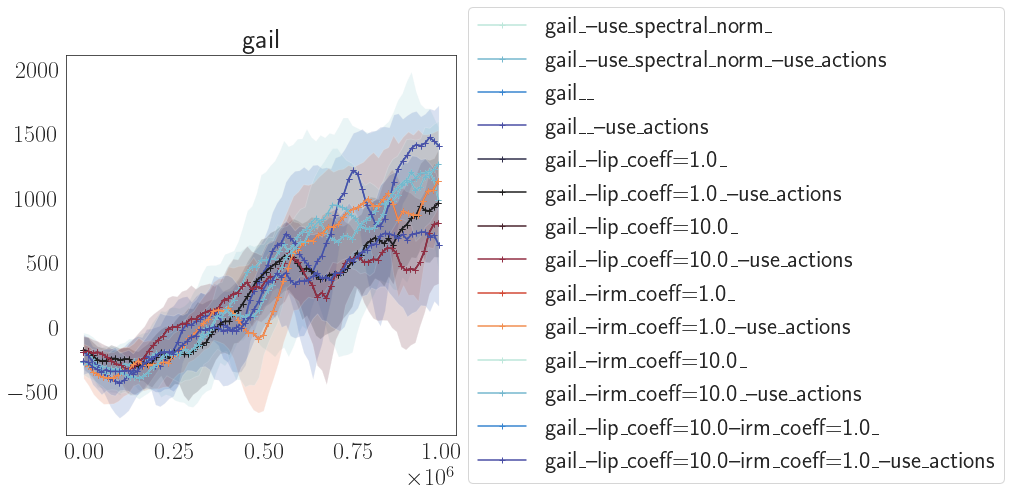

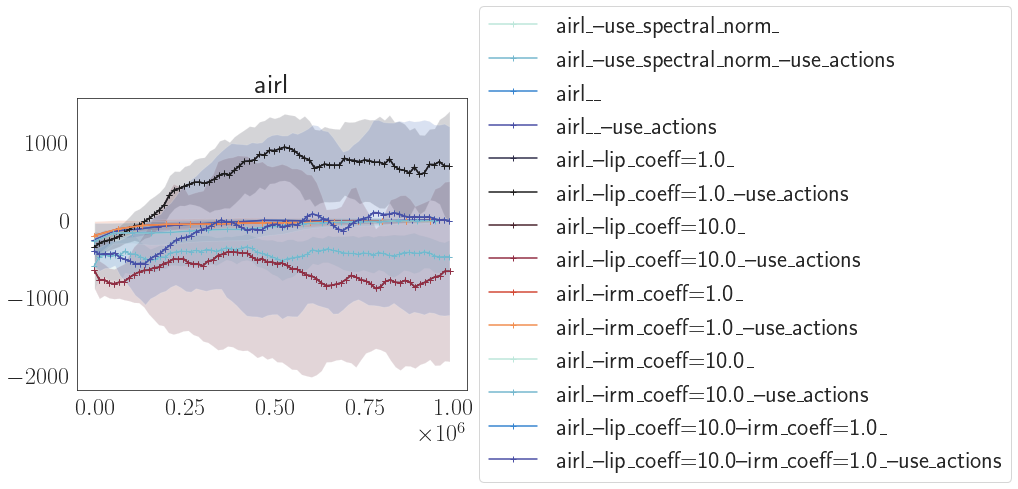

In [80]:
plot_comp('Ant-v3', ['gail', 'airl'], d_mustd, lins) 

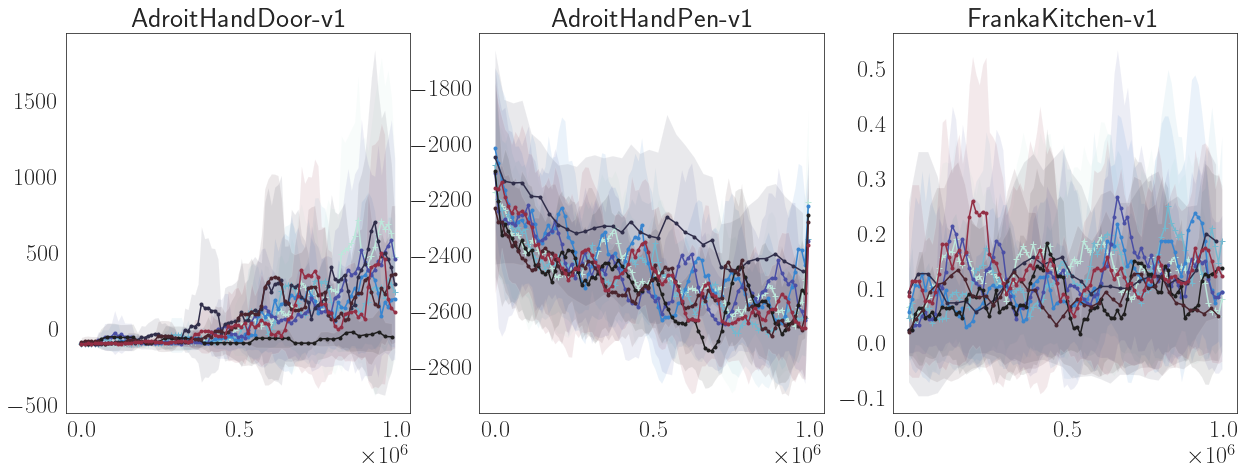

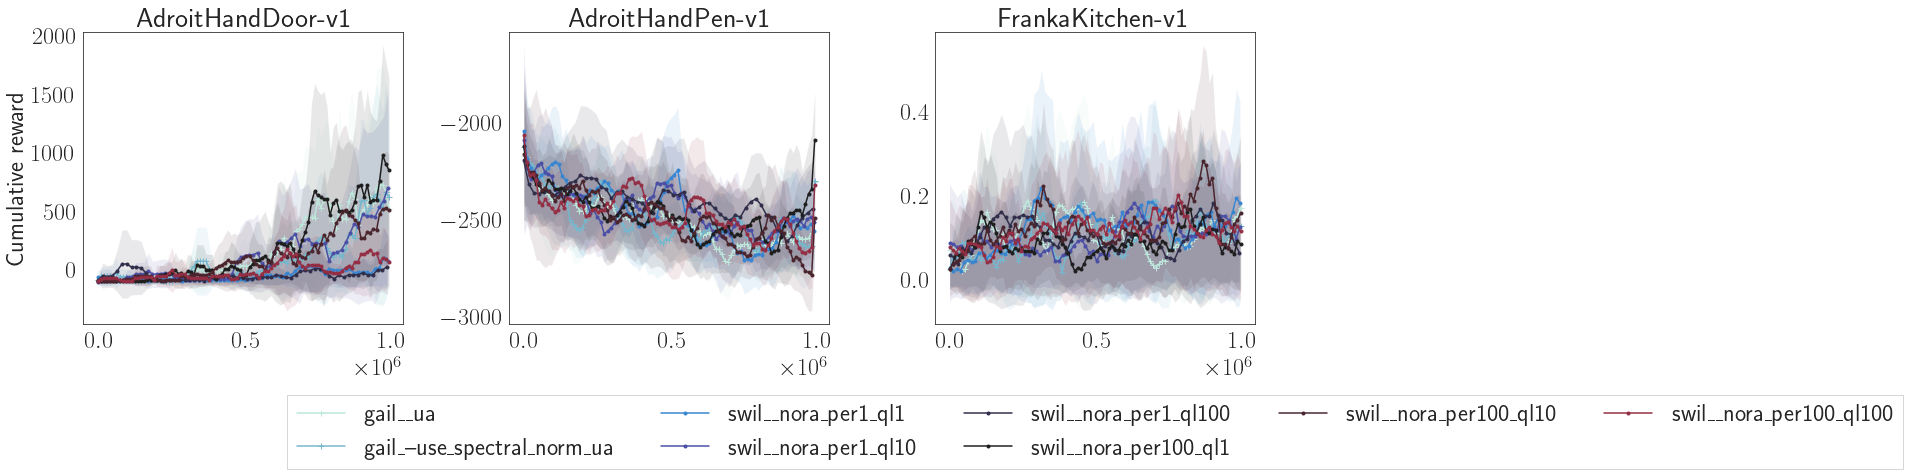

In [118]:
plot_comp(d_mustd_swil, d_ms_gail=d_mustd_gail, n_demo=[1,10], nobs_swil=[''], swil_per=[1,100], swil_ql=[1,10,100])

In [ ]:
font_size = 32
matplotlib.rcParams['font.size'] = font_size
matplotlib.rcParams["font.weight"] = "bold"
matplotlib.rcParams['text.usetex'] = False
matplotlib.rcParams['axes.labelsize'] = font_size
matplotlib.rcParams['axes.titlesize'] = font_size
matplotlib.rcParams['legend.fontsize'] = 28
matplotlib.rcParams['xtick.labelsize'] = font_size
matplotlib.rcParams['ytick.labelsize'] = font_size
sns.set_style(style='white')
#matplotlib.rcParams['text.latex.preamble']=r'\usepackage{amsmath} \DeclareMathOperator{\F}{F} \DeclareMathOperator{\GMF}{GMF} \DeclareMathOperator{\MLP}{MLP}'

In [ ]:
for ss in [1,20,100]:
    for ql in [1, 5, 10]:
        for n_d in [1,4,10]:
            plot_comp(d_mustd_swil, d_mustd_gail, n_demo=n_d, swil_ql=ql, ss=ss, subsample_plot=1)

### Ablation study 1: data sparse setting (plot)

In [ ]:
def plot_comp_ss(env, nob_swils, swil_ql_, d_ms_swil, d_ms_gail, n_demo, subsample_plot=1, savefig=None):
    envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
    env_exp = [5150, 4050, 3607, 8900, 6249]
    subsamplings = [1,20,100]
    NUM_COLORS = 20
    #cm = plt.get_cmap('gist_rainbow')
    #cm = sns.color_palette("tab10", as_cmap=True)
    cm =sns.color_palette("icefire", as_cmap=True)

    fig, axs = plt.subplots(1,len(subsamplings), figsize=(20,6))
    #fig.suptitle(f"ss:{ss}_ql:{swil_ql}_nd:{n_demo}")
    for i, ss in enumerate(subsamplings):
        axs[i].set_title(f"{env}_ss:{ss}_nd:{n_demo}")
        axs[i].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])
        axs[i].axhline(env_exp[envs.index(env)], c='k')

        #for lin_gail in ['', '--irm_coeff=1.0', '--lip_coeff=1.0', '--use_spectral_norm', '--use_absorb_wrapper']:
        for lin_gail in ['', '--lip_coeff=1.0', '--use_spectral_norm']:
            mu, std = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_gail][''][f"per_-1"][f"ql_1"]
            mu, std = smooth_mu_std(mu,std)
            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            x = np.arange(len(mu))*1e6/len(mu)

            #axs[i].plot(x,mu, label=f"gail_{lin_gail}", marker='+')
            #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)
            mu, std = d_ms_gail[env][f"ss_{ss}"][f"nd_{n_demo}"][lin_gail]['--use_actions'][f"per_-1"][f"ql_1"]
            mu, std = smooth_mu_std(mu,std)

            mu = mu[::subsample_plot]
            std = std[::subsample_plot]
            x = np.arange(len(mu))*1e6/len(mu)

            axs[i].plot(x, mu, label=f"gail_{lin_gail}_ua", marker='+')
            axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)

        #for nob_swil in ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']:        
        #    for swil_ql in [1,5,10]:
        #for nob_swil in ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']:       
        for nob_swil in nob_swils:        
            for swil_ql in [swil_ql_]:
            #for nob_swil in ['--use_next_obs--use_actions--use_dones']:        
                mu, std = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][''][nob_swil][f"per_100"][f"ql_{swil_ql}"]
                mu, std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))*1e6/len(mu)

                #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                #axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)

                mu_, std_ = d_ms_swil[env][f"ss_{ss}"][f"nd_{n_demo}"]['--replace_atoms'][nob_swil][f"per_100"][f"ql_{swil_ql}"]
                mu_, std_ = smooth_mu_std(mu_,std_)
                mu_ = mu_[::subsample_plot]
                std_ = std_[::subsample_plot]
                # rescale
                x_ = np.arange(len(mu_))*1e6/len(mu_)
                
                if np.mean(mu_) > np.mean(mu):
                    #axs[i].plot(x_, mu_, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                    axs[i].plot(x_, mu_, label=f"swil_ra", marker='o')
                    axs[i].fill_between(x_,mu_+std_, mu_-std_, alpha=0.2)  
                else:
                    #axs[i].plot(x, mu, label=f"swil_{nob_swil}_{swil_ql}", marker='o')
                    axs[i].plot(x, mu, label=f"swil", marker='o')
                    axs[i].fill_between(x,mu+std, mu-std, alpha=0.2)                      

        #axs[i].set_xticks(['0','1M'])
        #axs[i].axis('equal')
        #axs[i].set_xlim(0,20)
    axs[0].set_ylabel("Cumulative reward")
    
    #axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
    fig.subplots_adjust(bottom=0.3, wspace=0.33)
    #plt.tight_layout()

    axs[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.2),fancybox=False, shadow=False, ncol=3)
    #plt.legend(loc="lower left", ncol=len(df.columns))
    if savefig is not None:
        plt.savefig(f"plots/{savefig}.png", dpi=300, bbox_inches='tight')
    

In [ ]:
for env in ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']:
    plot_comp_ss(env, d_mustd_swil, d_mustd_gail, 1)
    plot_comp_ss(env, d_mustd_swil, d_mustd_gail, 4)
    plot_comp_ss(env, d_mustd_swil, d_mustd_gail, 10)

In [ ]:
plot_comp_ss('Humanoid-v3', ['', '--use_actions','--use_next_obs--use_actions--use_dones'], 5, d_mustd_swil, d_mustd_gail, 1, savefig='ss_comp_humanoid_nd1')
plot_comp_ss('Humanoid-v3', ['', '--use_actions','--use_next_obs--use_actions--use_dones'], 10, d_mustd_swil, d_mustd_gail, 4, savefig='ss_comp_humanoid_nd4')
plot_comp_ss('Humanoid-v3', ['', '--use_actions','--use_next_obs--use_actions--use_dones'], 10, d_mustd_swil, d_mustd_gail, 10, savefig='ss_comp_humanoid_nd10')

### Ablation study 2 (histogram plot)
for Humanoid and Ant across all n_demos
Variations: measurable space (get sxs results)? queue length? Replace atoms

In [ ]:
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''

algos = ['sac']
disc_types = ['swil']
lins = ['', '--replace_atoms']
usenobs = ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']

qlens = [1,5,10]
subsamplings = [1,20,100]
periods = [100]
disc_nonlins = ['tanh']
print(lins)

for algo in X:
    for ss in subsamplings:
        for nob in usenobs:
            for per in periods:
                for ql in qlens:
                    for nonlin in disc_nonlins:
                        fig, axs = plt.subplots(1,5, figsize=(24,4))
                        fig.subplots_adjust(top=0.88)
                        fig.suptitle(f"{algo}_subsmpl:{ss}_{nob}_nonlin:{nonlin}_period:{per}_qlen:{ql}")
                        plt.style.use('ggplot')
                        #print(lin, nob, nonlin)
                        #plt.title(lin + nob + nonlin)
                        for i, env in enumerate(envs):

                            X_axis = np.arange(len(lins))

                            axs[i].set_title(env)
                            X_index = []
                            Y_mean = []
                            Y_std = []
                            ndem = [1,4,10]

                            for j,n_d in enumerate(ndem):
                                Y = []
                                Y_ = []

                                for k,lin in enumerate(lins):
                                    val_list = []
                                    for seed in [515, 234, 894, 322, 72]:
                                        ea = d_swil[env][seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['swil'][f"per_{per}"][f"ql_{ql}"]
                                        if not isinstance(ea,dict):
                                            df = create_df_from_ea(ea, tags[-1])
                                            val_list.append(np.max(df['Value']))

                                    if len(val_list) > 0:
                                        Y.append(np.mean(val_list))
                                        Y_.append(np.std(val_list))
                                    else:
                                        Y.append(0)            
                                        Y_.append(0)

                                #print(f"{env_name}[seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['swil'][f"per_{per}"][f"ql_{ql}"Y, Y_)

                                axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2, label=f"{n_d} traj") 
                                axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 


                        axs[0].set_ylabel("Cumulative reward")
                        axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))

                        #plt.legend()
                        plt.tight_layout()

## Table 1

In [ ]:
for ss in subsamplings:
    for n_demo in n_demos:
        for lin in lins:
            for ua in usenobs:
                for per in periods:
                    for qlen in qlens:
                        env = 'HalfCheetah-v3'
                        #print(env, f"ss_{ss}", f"nd_{n_demo}", lin, ua, f"per_{per}", f"ql_{qlen}")
                        #print(np.mean(d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"][f"ql_{qlen}"][0][-5:]))

lins = ['', '--irm_coeff=1.0', '--use_spectral_norm', '--lip_coeff=10.0--use_absorb_wrapper']
usenobs = ['', '--use_actions']

subsamplings = [1,20,100]
n_demos = [1]

for ss in subsamplings:
    for n_demo in n_demos:
        for lin in lins:
            for ua in usenobs:
                env = 'Ant-v3'
                print(env, f"ss_{ss}", f"nd_{n_demo}", lin, ua)
                print("mean", np.mean(d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][0][-5:]))
                print(np.mean(d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][1][-5:]))
                print("max", np.max(d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][0]))
                print(np.max(d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][1]))